<a href="https://colab.research.google.com/github/Vnooo13/Vnooo13/blob/main/Commit_ML_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [3]:
df = pd.read_csv('/content/data_raw - Sheet1.csv')

In [4]:
df

,Time(UTC/GMT),WindSpeed(knots),WindDir(deg),Hsig(m),Hmax(m),WindSea(m),PrimSwell(m),WindSeaDir(deg),WavePeriod(s),SurfCurrentSpd(cm/s)
0,2019-01-01 0:00:00,12,307,1.44698,2.38622,1.42337,0.00000,270,5,45.0
1,2019-01-01 3:00:00,12,307,1.40283,2.31767,1.38217,0.00000,270,5,44.0
2,2019-01-01 6:00:00,12,307,1.35867,2.24912,1.34096,0.00000,270,5,44.0
3,2019-01-01 9:00:00,12,307,1.31452,2.18058,1.29976,0.00000,270,5,44.0
4,2019-01-01 12:00:00,12,307,1.27036,2.11203,1.25856,0.00000,270,5,43.0
...,...,...,...,...,...,...,...,...,...,...
20458,2025-12-31 12:00:00,12,272,0.90667,1.51194,0.89302,0.01747,244,4,40.0
20459,2025-12-31 15:00:00,13,267,0.94993,1.58449,0.95541,0.01310,250,4,42.0
20460,2025-12-31 18:00:00,13,263,0.99320,1.65705,1.01779,0.00873,257,4,44.0
20461,2025-12-31 21:00:00,14,259,1.03646,1.72961,1.08018,0.00437,264,4,46.0


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
# 1. Copy dataframe agar data mentah df tetap aman
data = df.copy()


# EDA

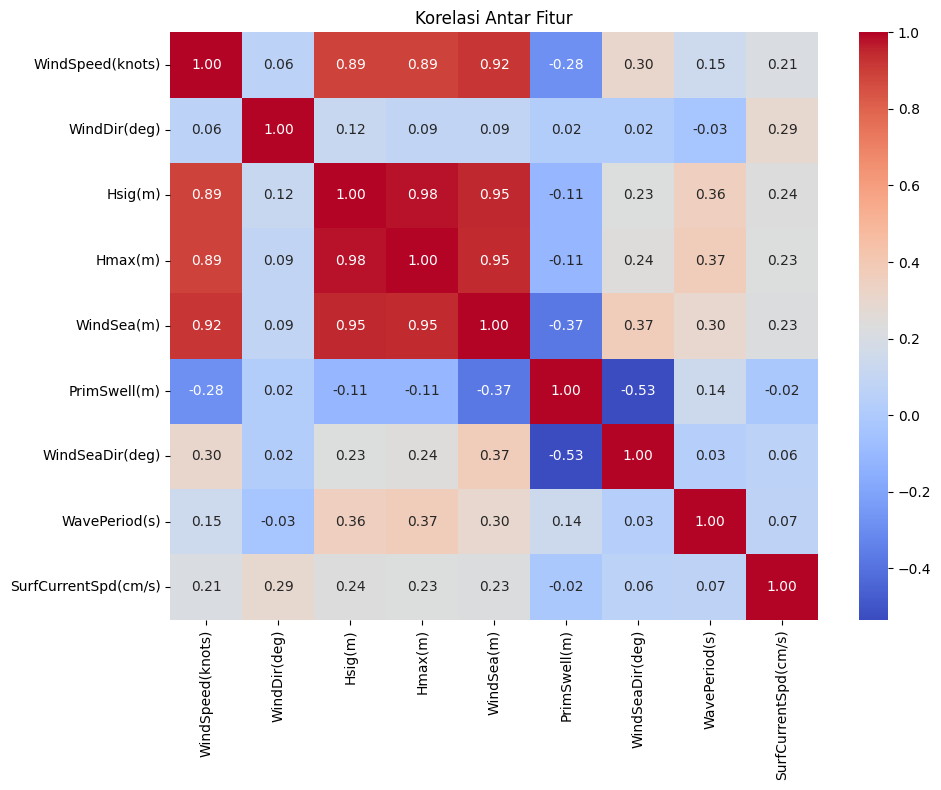

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
corr_matrix = data.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Korelasi Antar Fitur')
plt.tight_layout()
plt.show()

# PREPOS

In [8]:
# 2. Parsing waktu dan urutkan secara kronologis
data['Time(UTC/GMT)'] = pd.to_datetime(data['Time(UTC/GMT)'])
data = data.sort_values('Time(UTC/GMT)').reset_index(drop=True)

In [9]:
# 3. Feature Engineering Fisik: Ubah derajat arah angin & gelombang menjadi vektor (Sin & Cos)
# Agar model paham bahwa 359 derajat dan 0 derajat itu berdekatan
data['WindDir_sin'] = np.sin(np.deg2rad(data['WindDir(deg)']))
data['WindDir_cos'] = np.cos(np.deg2rad(data['WindDir(deg)']))
data['WindSeaDir_sin'] = np.sin(np.deg2rad(data['WindSeaDir(deg)']))
data['WindSeaDir_cos'] = np.cos(np.deg2rad(data['WindSeaDir(deg)']))

In [11]:
# ==============================================================================
# 4. Feature Engineering Time-Series: Riwayat Masa Lalu hingga t-24 Jam (8 steps)
# ==============================================================================
lag_cols = [
    'WindSpeed(knots)', 'Hsig(m)', 'Hmax(m)', 'WindSea(m)',
    'PrimSwell(m)', 'WavePeriod(s)', 'SurfCurrentSpd(cm/s)'
]

# 1 step = 3 jam, 2 steps = 6 jam, 4 steps = 12 jam, 8 steps = 24 jam lalu
lag_steps = [1, 2, 4, 8]

for col in lag_cols:
    # A. Lag Features (Sampling hingga 24 jam lalu)
    for step in lag_steps:
        hours = step * 3
        data[f'{col}_lag_{hours}h'] = data[col].shift(step)

    # B. Rolling Statistics: Jendela 12 jam (window=4) & Jendela 24 jam (window=8)
    data[f'{col}_roll_mean_12h'] = data[col].rolling(window=4).mean()
    data[f'{col}_roll_std_12h']  = data[col].rolling(window=4).std()
    data[f'{col}_roll_mean_24h'] = data[col].rolling(window=8).mean()
    data[f'{col}_roll_std_24h']  = data[col].rolling(window=8).std()

In [12]:
# ==============================================================================
# 5. Buat Target Prediksi 12 Jam ke Depan (t+4 steps)
# ==============================================================================
# shift(-4) mengambil baris ke-4 di masa depan (4 steps * 3 jam = 12 jam ke depan)
data['Hsig_next'] = data['Hsig(m)'].shift(-4)

# Hapus baris NaN di awal (akibat lag 8 baris) dan di akhir (akibat target masa depan 4 baris)
data = data.dropna().reset_index(drop=True)

In [13]:

# 6. Kategorisasi Target berdasarkan 4 kelas pada gambar referensi:
# 0: Sangat Rendah (< 0.5 m)
# 1: Rendah (0.5 - 1.0 m)
# 2: Sedang (1.0 - 1.25 m)
# 3: Tinggi (> 1.25 m)
bins = [-np.inf, 0.5, 1.0, 1.25, np.inf]
labels = [0, 1, 2, 3]
label_names = ['Sangat Rendah (<0.5m)', 'Rendah (0.5-1.0m)', 'Sedang (1.0-1.25m)', 'Tinggi (>1.25m)']

data['Target_Class'] = pd.cut(data['Hsig_next'], bins=bins, labels=labels).astype(int)

print("Ukuran data setelah Feature Engineering:", data.shape)
print("\nDistribusi Kelas Target:")
for idx, name in enumerate(label_names):
    count = (data['Target_Class'] == idx).sum()
    pct = count / len(data) * 100
    print(f"Kelas {idx} - {name}: {count} baris ({pct:.2f}%)")

Ukuran data setelah Feature Engineering: (20451, 72)

Distribusi Kelas Target:
Kelas 0 - Sangat Rendah (<0.5m): 9133 baris (44.66%)
Kelas 1 - Rendah (0.5-1.0m): 7757 baris (37.93%)
Kelas 2 - Sedang (1.0-1.25m): 2134 baris (10.43%)
Kelas 3 - Tinggi (>1.25m): 1427 baris (6.98%)


# SMOTE

In [14]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler


In [15]:

# 1. Tentukan kolom fitur (kecualikan kolom waktu dan target masa depan)
exclude_cols = ['Time(UTC/GMT)', 'Hsig_next', 'Target_Class', 'WindDir(deg)', 'WindSeaDir(deg)']
feature_cols = [c for c in data.columns if c not in exclude_cols]

# 2. Temporal Train-Test Split (2019-2024 untuk Train, 2025-2026 untuk Test)
train_df = data[data['Time(UTC/GMT)'] < '2025-01-01'].copy()
test_df  = data[data['Time(UTC/GMT)'] >= '2025-01-01'].copy()

X_train = train_df[feature_cols].values
y_train = train_df['Target_Class'].values

X_test  = test_df[feature_cols].values
y_test  = test_df['Target_Class'].values


In [16]:
# ==============================================================================
# 3 & 4. Imbalance Data Handling (SMOTE) & Data Augmentation + Visualisasi
# ==============================================================================
# Proses SMOTE pada data Train
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Injeksi Gaussian Noise ringan (Jittering) untuk simulasi fluktuasi sensor
np.random.seed(42)
noise = np.random.normal(loc=0.0, scale=0.01, size=X_train_smote.shape) * np.std(X_train, axis=0)
X_train_final = X_train_smote + noise
y_train_final = y_train_smote

# 1. Buat Tabel Ringkasan Distribusi Kelas (Sebelum vs Sesudah SMOTE vs Data Test)
train_before = pd.Series(y_train).value_counts().sort_index()
train_after  = pd.Series(y_train_final).value_counts().sort_index()
test_counts  = pd.Series(y_test).value_counts().sort_index()

summary_df = pd.DataFrame({
    'Kategori Gelombang': label_names,
    'Train Asli (2019-2024)': train_before.values,
    'Train % (Asli)': (train_before.values / len(y_train) * 100).round(2),
    'Train Final (SMOTE + Noise)': train_after.values,
    'Data Test (2025-2026)': test_counts.values,
    'Test %': (test_counts.values / len(y_test) * 100).round(2)
})


In [17]:

print("="*85)
print(f"RINGKASAN PEMBAGIAN DATA TEMPORAL & PENANGANAN IMBALANCE")
print(f"Total Sampel: {len(data):,} baris | Train (2019-2024): {len(X_train):,} | Test (2025+): {len(X_test):,}")
print(f"Total Train Setelah SMOTE & Augmentasi: {len(X_train_final):,} baris")
print("="*85)
display(summary_df.style.background_gradient(cmap='Blues', subset=['Train Asli (2019-2024)', 'Train Final (SMOTE + Noise)', 'Data Test (2025-2026)']))


RINGKASAN PEMBAGIAN DATA TEMPORAL & PENANGANAN IMBALANCE
Total Sampel: 20,451 baris | Train (2019-2024): 17,533 | Test (2025+): 2,918
Total Train Setelah SMOTE & Augmentasi: 32,232 baris


,Kategori Gelombang,Train Asli (2019-2024),Train % (Asli),Train Final (SMOTE + Noise),Data Test (2025-2026),Test %
0,Sangat Rendah (<0.5m),8058,45.960000,8058,1075,36.840000
1,Rendah (0.5-1.0m),6405,36.530000,8058,1352,46.330000
2,Sedang (1.0-1.25m),1806,10.300000,8058,328,11.240000
3,Tinggi (>1.25m),1264,7.210000,8058,163,5.590000


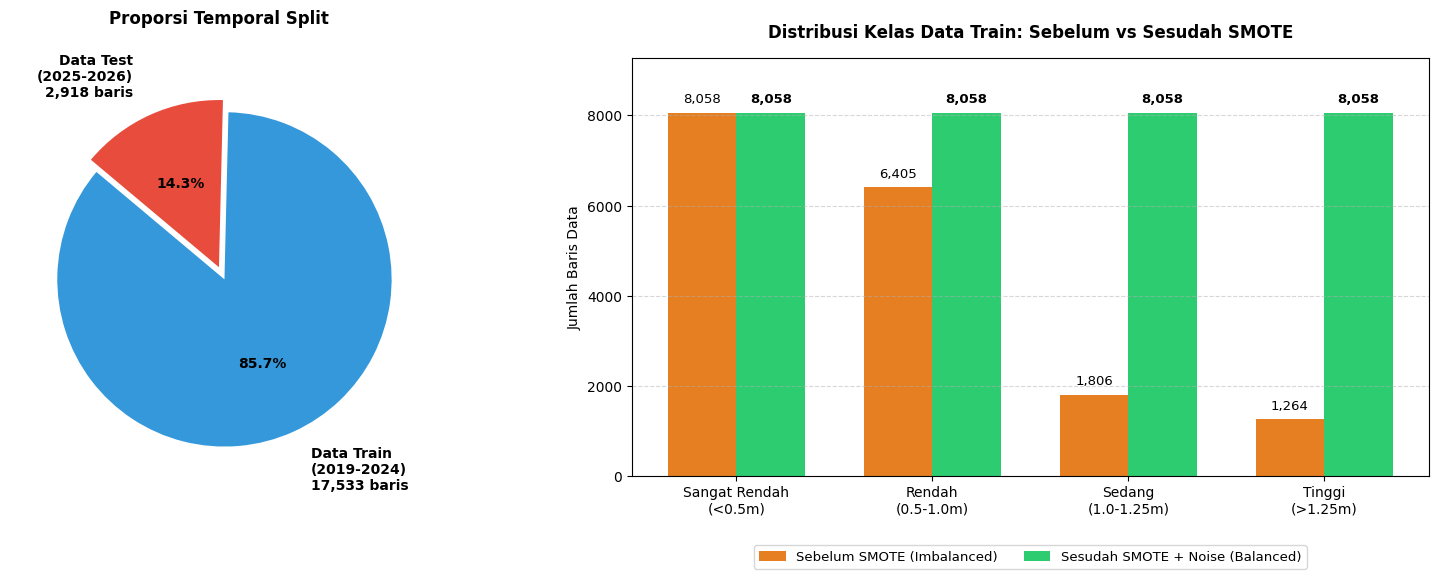

In [18]:
# 2. Visualisasi Grafik (Optimasi Spasi & Layout Bebas Overlapping - Legend di Bawah)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1, 1.3]})

# Panel Kiri: Proporsi Temporal Split (Train vs Test)
split_counts = [len(X_train), len(X_test)]
split_labels = [
    f'Data Train\n(2019-2024)\n{len(X_train):,} baris',
    f'Data Test\n(2025-2026)\n{len(X_test):,} baris'
]
colors_pie = ['#3498db', '#e74c3c']

wedges, texts, autotexts = axes[0].pie(
    split_counts,
    labels=split_labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_pie,
    explode=(0.08, 0),
    labeldistance=1.25,
    pctdistance=0.55,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[0].set_title('Proporsi Temporal Split', fontsize=12, weight='bold', pad=25)

# Panel Kanan: Bar Chart Sebelum vs Sesudah SMOTE + Augmentasi
x_idx = np.arange(len(label_names))
width = 0.35

rects1 = axes[1].bar(x_idx - width/2, train_before.values, width, label='Sebelum SMOTE (Imbalanced)', color='#e67e22')
rects2 = axes[1].bar(x_idx + width/2, train_after.values, width, label='Sesudah SMOTE + Noise (Balanced)', color='#2ecc71')

axes[1].set_title('Distribusi Kelas Data Train: Sebelum vs Sesudah SMOTE', fontsize=12, weight='bold', pad=15)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(['Sangat Rendah\n(<0.5m)', 'Rendah\n(0.5-1.0m)', 'Sedang\n(1.0-1.25m)', 'Tinggi\n(>1.25m)'], fontsize=10)
axes[1].set_ylabel('Jumlah Baris Data', fontsize=10)

# Memindahkan legend ke bawah grafik (di bawah sumbu X) agar tidak menghalangi angka
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True, fontsize=9.5)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Tambahkan label angka di atas batang dengan padding aman
for rect in rects1:
    h = rect.get_height()
    axes[1].annotate(f'{h:,}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 5),
                     textcoords="offset points", ha='center', va='bottom', fontsize=9.5)
for rect in rects2:
    h = rect.get_height()
    axes[1].annotate(f'{h:,}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 5),
                     textcoords="offset points", ha='center', va='bottom', fontsize=9.5, weight='bold')

# Naikkan batas atas Y-axis agar ada ruang kosong untuk anotasi angka
axes[1].set_ylim(0, max(train_after.values) * 1.15)

# Atur jarak antar subplot agar tidak bertabrakan dengan legend bawah
plt.tight_layout(pad=3.0)
plt.show()

# ML



In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, confusion_matrix


In [20]:

# 1. Definisi 4 Model
# Baseline (Model Tunggal)
dt_baseline = DecisionTreeClassifier(max_depth=8, random_state=42)

# Ensemble 1 (Bagging)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)

# Ensemble 2 (Boosting)
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.05,
    random_state=42,
    eval_metric='mlogloss',
    n_jobs=-1
)

# Ensemble 3 (Soft Voting: Gabungan probabilitas RF + XGBoost)
voting_model = VotingClassifier(
    estimators=[('rf', rf_model), ('xgb', xgb_model)],
    voting='soft',
    n_jobs=-1
)

models = {
    '1. Baseline (Decision Tree)': dt_baseline,
    '2. Ensemble Bagging (Random Forest)': rf_model,
    '3. Ensemble Boosting (XGBoost)': xgb_model,
    '4. Ensemble Voting (RF + XGBoost)': voting_model
}


In [21]:

# 2. Training & Evaluasi
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_final, y_train_final)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    recall_tinggi = recall_score(y_test, y_pred, labels=[3], average='macro', zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': acc,
        'F1-Macro': f1_macro,
        'F1-Weighted': f1_weighted,
        'Recall Kelas Tinggi (>1.25m)': recall_tinggi
    })

results_df = pd.DataFrame(results)


In [22]:
results_df

,Model,Accuracy,F1-Macro,F1-Weighted,Recall Kelas Tinggi (>1.25m)
0,1. Baseline (Decision Tree),0.869774,0.827939,0.872334,0.791411
1,2. Ensemble Bagging (Random Forest),0.891021,0.852375,0.892937,0.920245
2,3. Ensemble Boosting (XGBoost),0.901302,0.867874,0.902342,0.883436
3,4. Ensemble Voting (RF + XGBoost),0.899931,0.866841,0.901330,0.907975


In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

simplified_results = []
for name, model in models.items():
    y_pred = predictions[name]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_test, y_pred, average='macro', zero_division=0)

    simplified_results.append({
        'Model': name,
        'Akurasi': acc,
        'Precision (Macro)': prec,
        'Recall (Macro)': rec,
        'F1-Score (Macro)': f1
    })


In [24]:

simplified_results_df = pd.DataFrame(simplified_results)
simplified_results_df

,Model,Akurasi,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,1. Baseline (Decision Tree),0.869774,0.817384,0.843418,0.827939
1,2. Ensemble Bagging (Random Forest),0.891021,0.829409,0.881602,0.852375
2,3. Ensemble Boosting (XGBoost),0.901302,0.852358,0.886265,0.867874
3,4. Ensemble Voting (RF + XGBoost),0.899931,0.847312,0.890825,0.866841



=== Classification Report: Ensemble Voting (RF + XGBoost) ===
                       precision    recall  f1-score   support

Sangat Rendah (<0.5m)       0.93      0.95      0.94      1075
    Rendah (0.5-1.0m)       0.94      0.88      0.91      1352
   Sedang (1.0-1.25m)       0.71      0.83      0.77       328
      Tinggi (>1.25m)       0.80      0.91      0.85       163

             accuracy                           0.90      2918
            macro avg       0.85      0.89      0.87      2918
         weighted avg       0.91      0.90      0.90      2918



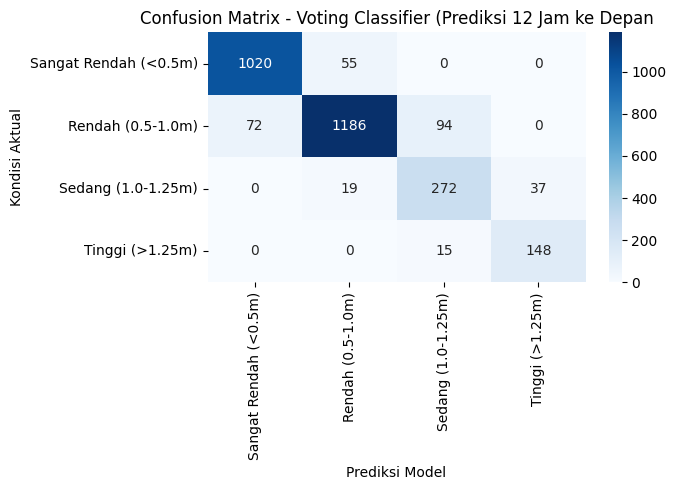

In [25]:

# 3. Classification Report & Confusion Matrix untuk Ensemble Voting
print("\n=== Classification Report: Ensemble Voting (RF + XGBoost) ===")
print(classification_report(y_test, predictions['4. Ensemble Voting (RF + XGBoost)'], target_names=label_names))

plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, predictions['4. Ensemble Voting (RF + XGBoost)'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.title('Confusion Matrix - Voting Classifier (Prediksi 12 Jam ke Depan')
plt.xlabel('Prediksi Model')
plt.ylabel('Kondisi Aktual')
plt.tight_layout()
plt.show()